# EDA: вердикты судьи на двух курсах

Состав, объём и качество данных проверки студенческих работ судьёй, срез на 8 ноября 2026 года.
Два курса: 4 курс «Системы ИИ» (командный проект: документы, код и сборка) и практика 3 курса
(исследовательская работа: обзор литературы и план эксперимента). Цель анализа: понять, на каких
данных можно мерить судью и что мешает это делать.

Таблицы лежат в `data/eda/` и обезличены скриптом `scripts/anonymize_eda.py`: курсы и команды
заменены кодами, даты неделями, отметок приёмки по командам нет. Репозитории практики закрытые,
поэтому по ней опубликованы только сводки: счётчики по критериям и неделям, гистограмма времени
и итоговые числа в `c3_summary.json`. Описание полей: `data/eda/README.md`. Авторы работ обоих
курсов согласились на использование данных для оценки качества.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path("..") if Path("../data/eda").exists() else Path()
DATA = ROOT / "data" / "eda"
# Картинки отдельно: отчёт reports/eda.md читают прямо на GitHub
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#6b6b68", "#e6e5e1"
COURSES = {"c4": "4 курс", "c3": "практика 3 курса"}
COURSE_COLOR = {"c4": "#2a78d6", "c3": "#eb6834"}
STATES = {"closed": "#0ca30c", "open": "#d03b3b", "unsure": "#fab219"}
NAMES = {"closed": "закрыт", "open": "не закрыт", "unsure": "не уверен"}
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "font.size": 11,
        "axes.edgecolor": GRID,
        "axes.labelcolor": MUTED,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": GRID,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlelocation": "left",
        "axes.titlesize": 13,
        "figure.dpi": 110,
    }
)

# 4 курс построчно
verdicts = pd.read_csv(DATA / "verdicts.csv")
runs = pd.read_csv(DATA / "runs.csv")
reviews = pd.read_csv(DATA / "reviews.csv")
data = verdicts.merge(
    runs[["run", "trigger", "agent", "status", "week"]], on="run", how="left"
)
new = data[data["agent"] == "0.1.0"].copy()
new_runs = runs[(runs["agent"] == "0.1.0") & (runs["status"] == "done")]
# практика только сводками
c3_counts = pd.read_csv(DATA / "c3_verdict_counts.csv")
c3_weeks = pd.read_csv(DATA / "c3_runs_by_week.csv")
c3_hist = pd.read_csv(DATA / "c3_minutes_hist.csv")
c3 = json.loads((DATA / "c3_summary.json").read_text(encoding="utf-8"))
# оба курса сводкой
questions = pd.read_csv(DATA / "questions_summary.csv")
rechecks = pd.read_csv(DATA / "rechecks_summary.csv")


def table(c4, c3_values):
    return pd.DataFrame(
        {COURSES["c4"]: pd.Series(c4), COURSES["c3"]: pd.Series(c3_values)}
    )

## 1. Состав и объём

In [2]:
team_sizes = new.groupby("team").size()
table(
    {
        "команд": verdicts.team.nunique(),
        "работ": verdicts.work.nunique(),
        "критериев": verdicts.criterion.nunique(),
        "прогонов нового судьи": len(new_runs),
        "вердиктов нового судьи": len(new),
        "вердиктов на команду, медиана": team_sizes.median(),
        "вердиктов на команду, мин и макс": f"от {team_sizes.min()} до {team_sizes.max()}",
        "закрытых приёмок": len(reviews),
    },
    {
        "команд": c3["teams"],
        "работ": c3_counts.work.nunique(),
        "критериев": c3_counts.criterion.nunique(),
        "прогонов нового судьи": c3["runs_done"],
        "вердиктов нового судьи": c3["verdicts"],
        "вердиктов на команду, медиана": c3["verdicts_per_team"]["median"],
        "вердиктов на команду, мин и макс": f"от {c3['verdicts_per_team']['min']} до {c3['verdicts_per_team']['max']}",
        "закрытых приёмок": c3["reviews"],
    },
)

,4 курс,практика 3 курса
команд,8,31
работ,6,2
критериев,82,10
прогонов нового судьи,106,116
вердиктов нового судьи,355,1410
"вердиктов на команду, медиана",39.5,42.0
"вердиктов на команду, мин и макс",от 11 до 80,от 6 до 138
закрытых приёмок,25,59


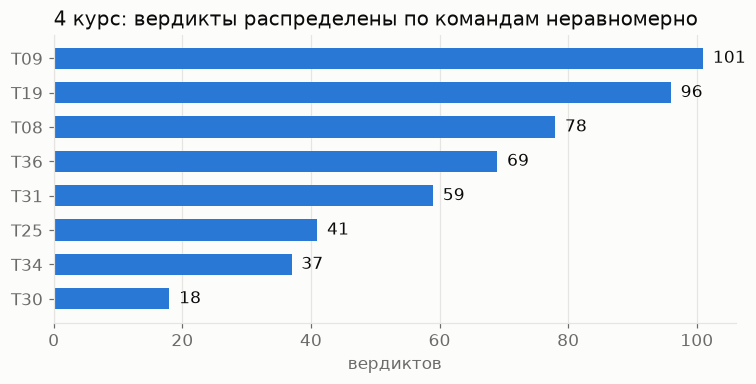

In [3]:
by_team = verdicts.groupby("team").size().sort_values()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(by_team.index, by_team.values, color=COURSE_COLOR["c4"], height=0.62)
for y, value in enumerate(by_team.values):
    ax.text(value + 1.5, y, str(value), va="center", color=INK)
ax.set_title("4 курс: вердикты распределены по командам неравномерно")
ax.set_xlabel("вердиктов")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "01_verdicts_by_team.png", dpi=150, bbox_inches="tight")
plt.show()

**Вывод.** На 4 курсе 8 команд и 355 вердиктов нового судьи, на практике 31 группа и 1410 вердиктов. Вердикты внутри команды похожи, поэтому настоящий размер выборки определяет число команд: с практикой их стало 39 вместо 8, и интервалы по командам станут заметно уже. Неравномерность есть на обоих курсах: от 11 до 80 вердиктов на команду на 4 курсе и от 6 до 138 на практике. Значит, эталон отбираем с разбивкой по командам. На графике 4 курса учтён и перенос со старой платформы.

## 2. Качество данных

In [4]:
disputes = questions[questions.dispute != "none"].groupby("course")["count"].sum()
table(
    {
        "прогонов перенесено со старой платформы": (runs.trigger == "import").sum(),
        "вердиктов без типа проверки": verdicts.check_type.isna().sum(),
        "упавших прогонов": (runs.status == "failed").sum(),
        "самая длинная приёмка, минут": int(reviews.minutes.max()),
        "медиана приёмки по таймеру, минут": reviews.minutes.median(),
        "отметок «агент ошибся»": int(disputes.get("c4", 0)),
    },
    {
        "прогонов перенесено со старой платформы": 0,
        "вердиктов без типа проверки": 0,
        "упавших прогонов": c3["runs_failed"],
        "самая длинная приёмка, минут": "только медиана",
        "медиана приёмки по таймеру, минут": c3["review_minutes_median"],
        "отметок «агент ошибся»": int(disputes.get("c3", 0)),
    },
)

,4 курс,практика 3 курса
прогонов перенесено со старой платформы,50.0,0
вердиктов без типа проверки,144.0,0
упавших прогонов,2.0,7
"самая длинная приёмка, минут",5263.0,только медиана
"медиана приёмки по таймеру, минут",29.0,1.0
отметок «агент ошибся»,0.0,51


**Вывод.** На 4 курсе 50 прогонов перенесены со старой платформы без типа проверки и настоящего времени, дальше их не считаем; у одной приёмки таймер показывает 5263 минуты. Практику целиком проверял новый судья, но 7 прогонов упали. Приёмка на практике ручная: её проводят вне платформы и потом закрывают одной записью, поэтому таймер показывает около минуты, и время приёмки практики как метрика не годится. Метка версии у новых прогонов одна, хотя подсказки менялись. Отметки «агент ошибся» есть только на практике, их 51.

## 3. Что отвечает судья

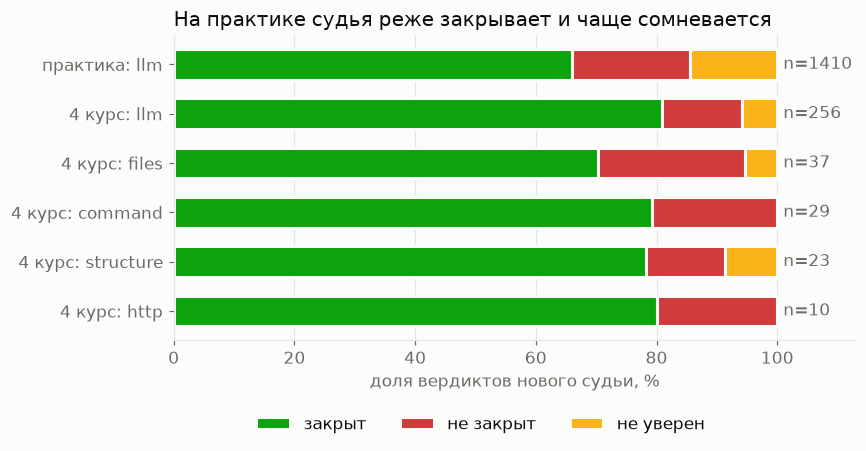

,4 курс,практика 3 курса
state,,
закрыт,0.794,0.660
не закрыт,0.152,0.195
не уверен,0.054,0.145


In [5]:
c4_groups = (
    new.assign(group="4 курс: " + new.check_type)
    .groupby(["group", "state"])
    .size()
    .unstack(fill_value=0)
)
c3_groups = c3_counts.assign(group="практика: " + c3_counts.check_type).pivot_table(
    index="group", columns="state", values="count", aggfunc="sum", fill_value=0
)
share = pd.concat([c4_groups, c3_groups]).reindex(columns=list(STATES), fill_value=0)
share = share.loc[
    sorted(share.index, key=lambda g: (g.startswith("практика"), share.loc[g].sum()))
]
parts = share.div(share.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(8, 3.6))
left = pd.Series(0.0, index=parts.index)
for state, color in STATES.items():
    ax.barh(
        parts.index,
        parts[state],
        left=left,
        color=color,
        height=0.62,
        label=NAMES[state],
        edgecolor=SURFACE,
        linewidth=2,
    )
    left = left + parts[state]
for y, name in enumerate(parts.index):
    ax.text(101, y, f"n={share.loc[name].sum()}", va="center", color=MUTED)
ax.set_xlim(0, 113)
ax.set_title("На практике судья реже закрывает и чаще сомневается")
ax.set_xlabel("доля вердиктов нового судьи, %")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, ncols=3, loc="upper center", bbox_to_anchor=(0.45, -0.2))
fig.savefig(FIG / "02_states_by_course_and_type.png", dpi=150, bbox_inches="tight")
plt.show()
c3_state = c3_counts.groupby("state")["count"].sum()
table(
    new.state.value_counts(normalize=True).reindex(list(STATES)).round(3).rename(NAMES),
    (c3_state / c3_state.sum()).reindex(list(STATES)).round(3).rename(NAMES),
)

In [6]:
c4_hard = new.groupby("criterion").state.agg(
    trouble=lambda s: (s != "closed").sum(),
    closed=lambda s: round((s == "closed").mean(), 2),
)
c3_crit = c3_counts.pivot_table(
    index="criterion", columns="state", values="count", aggfunc="sum", fill_value=0
)
c3_hard = pd.DataFrame(
    {
        "trouble": c3_crit.sum(axis=1) - c3_crit.get("closed", 0),
        "closed": (c3_crit.get("closed", 0) / c3_crit.sum(axis=1)).round(2),
    }
)
pd.concat(
    {
        COURSES["c4"]: c4_hard.nlargest(4, "trouble"),
        COURSES["c3"]: c3_hard.nlargest(4, "trouble"),
    }
).rename(columns={"trouble": "не закрытых и сомнений", "closed": "доля закрытых"})

не закрытых и сомнений  доля закрытых
                 criterion                                                   
4 курс           lab2-erd-api                                9           0.44
                 lab1-research-sources                       8           0.00
                 lab2-golden-dataset                         7           0.42
                 lab2-compose-dev                            4           0.60
практика 3 курса rw-sources-real                           130           0.37
                 rw-cited-right                            110           0.47
                 rw-bib                                     78           0.62
                 rw-gap                                     63           0.70

**Вывод.** Практика для судьи труднее: закрыто 66% против 79% на 4 курсе, сомнений 15% против 5%. На практике всё проверяется пониманием текста (`llm`), а трудные критерии касаются источников: реальны ли источники (37% закрытых) и верно ли они процитированы (47%). Это другой тип работы, и он хорошо проверяет перенос судьи на чужой курс. Невыполненного на практике больше, поэтому она помогает и с редким классом.

## 4. Откуда берётся «не уверен» и насколько судья стабилен

In [7]:
voted = new[new.answers.notna()]
unsure = new[new.state == "unsure"]
chains = new.groupby(["team", "role", "criterion"], dropna=False).state.agg(
    ["nunique", "size"]
)
repeated = chains[chains["size"] > 1]
table(
    {
        "вердиктов с записанными ответами": len(voted),
        "доля, где ответы модели разошлись": round(voted.votes_split.mean(), 3),
        "вердиктов «не уверен»": len(unsure),
        "из них при единогласных ответах": int(
            (unsure.answers.notna() & ~unsure.votes_split).sum()
        ),
        "критериев, проверенных больше раза": len(repeated),
        "доля, где итог менялся": round((repeated["nunique"] > 1).mean(), 3),
    },
    {
        "вердиктов с записанными ответами": c3_counts.with_answers.sum(),
        "доля, где ответы модели разошлись": round(
            c3_counts.votes_split.sum() / c3_counts.with_answers.sum(), 3
        ),
        "вердиктов «не уверен»": c3_counts.loc[
            c3_counts.state == "unsure", "count"
        ].sum(),
        "из них при единогласных ответах": c3["unsure_unanimous"],
        "критериев, проверенных больше раза": c3["criteria_checked_twice"],
        "доля, где итог менялся": c3["criteria_changed_share"],
    },
)

,4 курс,практика 3 курса
вердиктов с записанными ответами,206.000,646.000
"доля, где ответы модели разошлись",0.073,0.108
вердиктов «не уверен»,19.000,204.000
из них при единогласных ответах,11.000,9.000
"критериев, проверенных больше раза",93.000,278.000
"доля, где итог менялся",0.430,0.281


**Вывод.** Ответы модели на практике расходятся чаще: в 10,8% вердиктов против 7,3% на 4 курсе. Откуда сомнения практики, по данным не восстановить: у 184 из 204 ответы модели не записаны. На 4 курсе 11 из 19 сомнений появились при единогласных ответах, то есть вердикт снимали правила. Итог критерия между проверками меняется в 28% случаев на практике и в 43% на 4 курсе, но сюда входят и доработки студентов; чистую повторяемость меряем на одном коммите.

## 5. Что видели люди

In [8]:
closed_c3 = c3_counts[c3_counts.state == "closed"]
coverage = table(
    {
        "закрытых вердиктов": (verdicts.state == "closed").sum(),
        "из них с вопросом к приёмке": (
            (verdicts.state == "closed") & verdicts.has_question
        ).sum(),
    },
    {
        "закрытых вердиктов": closed_c3["count"].sum(),
        "из них с вопросом к приёмке": closed_c3.has_question.sum(),
    },
)
names = {
    "answered": "ответил",
    "missed": "не ответил",
    "skipped": "пропущен",
    "none": "без отметки",
}
marks = questions.pivot_table(
    index="mark", columns="course", values="count", aggfunc="sum", fill_value=0
).rename(index=names, columns=COURSES)
disputes_table = (
    questions[questions.dispute != "none"]
    .pivot_table(
        index=["dispute", "verdict_state"],
        columns="course",
        values="count",
        aggfunc="sum",
        fill_value=0,
    )
    .rename(columns=COURSES)
)
display(coverage)
display(marks)
disputes_table

,4 курс,практика 3 курса
закрытых вердиктов,397,931
из них с вопросом к приёмке,226,631


course,практика 3 курса,4 курс
mark,,
ответил,695,267
не ответил,73,33
без отметки,48,343
пропущен,0,22


,course,практика 3 курса
dispute,verdict_state,
false_fail,open,47
false_pass,closed,4


**Вывод.** На практике вопрос к приёмке есть у 68% закрытых вердиктов (631 из 931), на 4 курсе у 57%. Все 51 отметка «агент ошибся» сделаны на практике: 47 «зря не закрыл» и 4 «зря закрыл». Это первые метки людей по критериям, но смещённые: отмечали только замеченные ошибки, поэтому долю ошибок по ним не посчитать. Видно другое: на практике судья скорее слишком строг. Отметка о вопросе по-прежнему говорит об ответе студента, а не о верности вердикта.

## 6. Время, нагрузка и токены

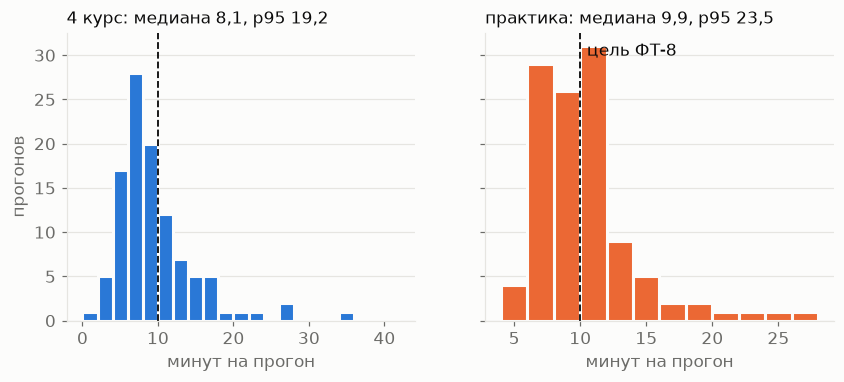

за пределами графика у практики: 4 прогона, максимум 97.31 мин


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
m4 = new_runs.minutes.dropna()
axes[0].hist(
    m4, bins=range(0, 44, 2), color=COURSE_COLOR["c4"], edgecolor=SURFACE, linewidth=2
)
axes[0].set_title(
    f"4 курс: медиана {m4.median():.1f}, p95 {m4.quantile(0.95):.1f}".replace(".", ","),
    fontsize=11,
)
shown = c3_hist[c3_hist.from_minute < 44]
axes[1].bar(
    shown.from_minute + 1,
    shown["count"],
    width=2,
    color=COURSE_COLOR["c3"],
    edgecolor=SURFACE,
    linewidth=2,
)
axes[1].set_title(
    f"практика: медиана {c3['minutes']['median']}, p95 {c3['minutes']['p95']}".replace(
        ".", ","
    ),
    fontsize=11,
)
for ax in axes:
    ax.axvline(10, color=INK, linewidth=1.2, linestyle="--")
    ax.set_xlabel("минут на прогон")
    ax.grid(axis="x", visible=False)
axes[1].text(10.5, axes[1].get_ylim()[1] * 0.92, "цель ФТ-8", color=INK)
axes[0].set_ylabel("прогонов")
fig.savefig(FIG / "03_run_minutes.png", dpi=150, bbox_inches="tight")
plt.show()
print(
    "за пределами графика у практики:",
    int(c3_hist.loc[c3_hist.from_minute >= 44, "count"].sum()),
    "прогона, максимум",
    c3["minutes"]["max"],
    "мин",
)

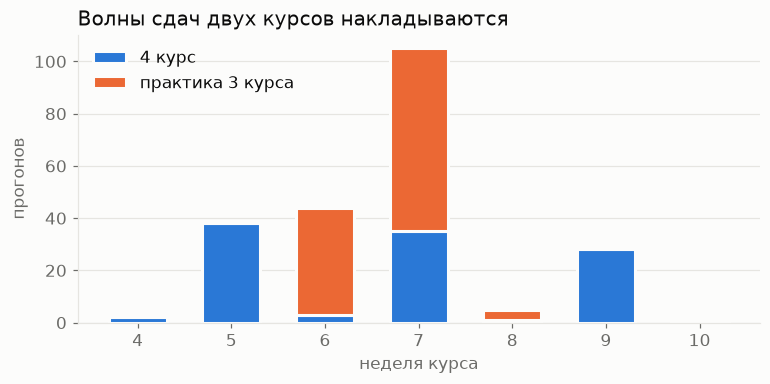

In [10]:
# перенос со старой платформы это не проверки, у практики его нет
w4 = runs[runs.trigger != "import"].groupby("week").size()
w3 = c3_weeks.groupby("week")["count"].sum()
weeks = range(
    int(min(w4.index.min(), w3.index.min())),
    int(max(w4.index.max(), w3.index.max())) + 1,
)
weekly = pd.DataFrame({"c4": w4, "c3": w3}).reindex(weeks, fill_value=0).fillna(0)
fig, ax = plt.subplots(figsize=(8, 3.4))
bottom = pd.Series(0.0, index=weekly.index)
for c in COURSES:
    ax.bar(
        weekly.index,
        weekly[c],
        bottom=bottom,
        color=COURSE_COLOR[c],
        width=0.62,
        label=COURSES[c],
        edgecolor=SURFACE,
        linewidth=2,
    )
    bottom = bottom + weekly[c]
ax.set_title("Волны сдач двух курсов накладываются")
ax.set_xlabel("неделя курса")
ax.set_ylabel("прогонов")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIG / "04_runs_by_week.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
usage = new_runs.dropna(subset=["tokens_in"]).assign(
    tokens=lambda d: d.tokens_in + d.tokens_out
)
table(
    {
        "токенов на прогон, медиана": int(usage.tokens.median()),
        "токенов на прогон, 95-й процентиль": int(usage.tokens.quantile(0.95)),
        "доля входа из кэша": round(
            usage.tokens_cached.sum() / usage.tokens_in.sum(), 3
        ),
    },
    {
        "токенов на прогон, медиана": int(c3["tokens_per_run"]["median"]),
        "токенов на прогон, 95-й процентиль": int(c3["tokens_per_run"]["p95"]),
        "доля входа из кэша": c3["cache_share"],
    },
)

,4 курс,практика 3 курса
"токенов на прогон, медиана",643604.000,738521.0
"токенов на прогон, 95-й процентиль",1474374.000,1405978.0
доля входа из кэша,0.811,0.8


**Вывод.** На практике прогон дольше: медиана 9,9 и 95-й процентиль 23,5 минуты против 8,1 и 19,2, максимум 97 минут; цель ФТ-8 в 10 минут не выполнена на обоих курсах. Волны курсов накладываются: на 7-й неделе вместе 105 прогонов, поэтому нагрузочный тест в ДЗ 4 строим на совмещённой волне, а не на среднем. Практика тратит больше токенов: около 740 тысяч на прогон против 640, доля кэша около 80% на обоих курсах.

## 7. Приёмка и перепроверки

In [12]:
rc = rechecks.pivot_table(
    index="kind", columns="course", values="count", aggfunc="sum", fill_value=0
)
table(
    {
        "закрытых приёмок": len(reviews),
        "медиана по таймеру, мин": reviews.minutes.median(),
        "запросов на перепроверку": int(rc["c4"].sum()),
        "из них от студентов": int(rc.loc["learner", "c4"]),
    },
    {
        "закрытых приёмок": c3["reviews"],
        "медиана по таймеру, мин": c3["review_minutes_median"],
        "запросов на перепроверку": int(rc["c3"].sum()),
        "из них от студентов": int(rc.loc["learner", "c3"]),
    },
)

,4 курс,практика 3 курса
закрытых приёмок,25.0,59.0
"медиана по таймеру, мин",29.0,1.0
запросов на перепроверку,42.0,63.0
из них от студентов,38.0,29.0


**Вывод.** Приёмка 4 курса по таймеру занимает около 29 минут. На практике приёмка ручная, таймер её не отражает, поэтому минуты приёмки как бизнес-метрику считаем только по 4 курсу. Студенты сами запросили 38 перепроверок на 4 курсе и 29 на практике, ещё 32 запросили преподаватели практики: вердиктами пользуются обе стороны.

## Итог

Что берём в работу:

1. **Эталон.** Около 150 вердиктов 4 курса и отдельная выборка практики, обе отобраны случайно с разбивкой по командам и работам и с запасом по трудным критериям.
2. **Деление данных.** 4 курс для правок, две его команды отложены; практика целиком становится отложенным курсом и проверяет перенос судьи на чужой курс.
3. **Метрики.** Ошибки среди закрытых и ложные «не закрыт» отдельно, а не общая точность. Интервалы строим бутстрепом по командам.
4. **Споры практики.** 51 отметка идёт в разбор ошибок, а не в оценку: она смещена.
5. **Повторы.** Несколько прогонов на одном коммите для настоящей повторяемости.
6. **Версии и ответы.** В платформе записывать хеш подсказок и ответы модели у каждого вердикта.